In [2]:
#Purpose of this notebook: explore the fire/smoke dataset and check the label format.

In [3]:
%pip install numpy matplotlib pillow


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install -q kagglehub


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install torch torchvision

In [7]:
import os
import kagglehub

DATA_DIR = kagglehub.dataset_download(
    "sayedgamal99/smoke-fire-detection-yolo"
    )

DATA_DIR = os.path.join(DATA_DIR, "data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
VAL_DIR = os.path.join(DATA_DIR, "val")

print("Train images:", len(os.listdir(os.path.join(TRAIN_DIR, "images"))))
print("Train labels:", len(os.listdir(os.path.join(TRAIN_DIR, "labels"))))
print("Test images:", len(os.listdir(os.path.join(TEST_DIR, "images"))))
print("Test labels:", len(os.listdir(os.path.join(TEST_DIR, "labels"))))

/home/philiproche/NeuralNetworks-Group26/myenv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train images: 14122
Train labels: 14122
Test images: 4306
Test labels: 4306


In [8]:
def read_labels(path):
    boxes = []
    with open(path, "r") as f:
        for line in f:
            parts = line.split()
            if len (parts) != 5:
                continue
            class_id, x_center, y_center, width, height = map(float, parts)
            class_id = int(class_id)
            boxes.append((class_id, x_center, y_center, width, height))
    return boxes

In [9]:
fire_and_smoke_labels = read_labels(os.path.join(TEST_DIR, "labels", "PublicDataset01075.txt"))
empty = read_labels(os.path.join(TEST_DIR, "labels", "AoF06723.txt"))

print("Fire and smoke labels:", len(fire_and_smoke_labels), "boxes")
for box in fire_and_smoke_labels:
    print("Box:", box)

print("Empty labels:", len(empty), "boxes")


Fire and smoke labels: 3 boxes
Box: (1, 0.23981481481481481, 0.6152777777777778, 0.0462962962962963, 0.05277777777777778)
Box: (1, 0.4898148148148148, 0.6486111111111111, 0.04259259259259259, 0.04166666666666667)
Box: (0, 0.5166666666666667, 0.3680555555555556, 0.7481481481481482, 0.675)
Empty labels: 0 boxes


## 2. Annotation visualisation

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

CLASS_NAMES = ["smoke", "fire"]           
COLOURS = ["deepskyblue", "orangered"]     

def show_boxes(image_path, boxes, title=None):
    img = Image.open(image_path)          
    W, H = img.size                        

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)                         # show the image

    for class_id, x_center, y_center, width, height in boxes:
        
        box_w = width * W                  # box width in pixels
        box_h = height * H                 # box height in pixels

        # Labels give the CENTRE of the box, but matplotlib needs the TOP-LEFT corner,
        # so move half the box width left and half the box height up from the centre
        x0 = (x_center - width / 2) * W    
        y0 = (y_center - height / 2) * H   # top edge in pixels

        rect = patches.Rectangle((x0, y0), box_w, box_h,
                                 fill=False, linewidth=2,
                                 edgecolor=COLOURS[class_id])   # colour by class
        ax.add_patch(rect)                                      # draw the box
        ax.text(x0, y0 - 5, CLASS_NAMES[class_id],
                color=COLOURS[class_id], fontsize=10)           

    ax.set_title(title if title else os.path.basename(image_path))
    ax.axis("off")                         # hide the pixel axes
    plt.show()

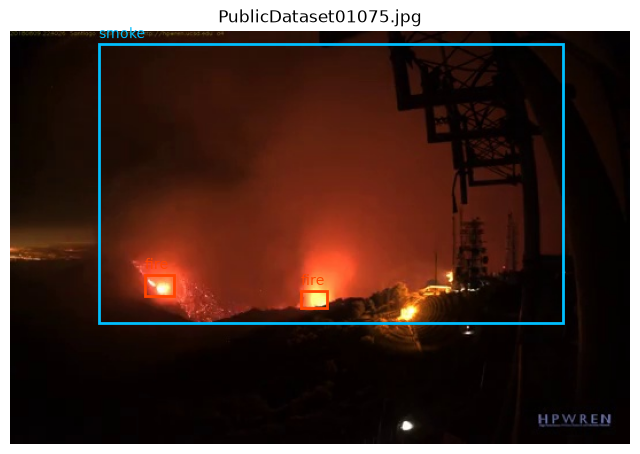

In [11]:
image_path = os.path.join(TEST_DIR, "images", "PublicDataset01075.jpg")
show_boxes(image_path, fire_and_smoke_labels)

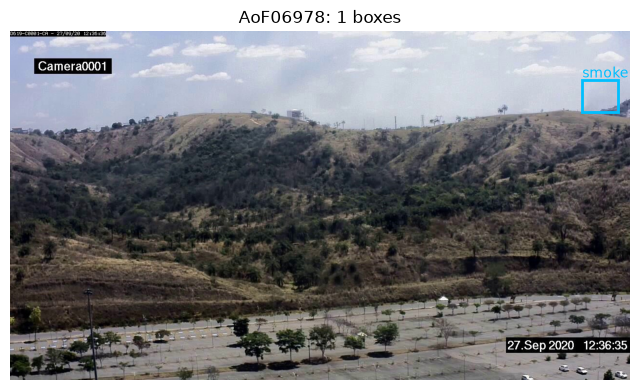

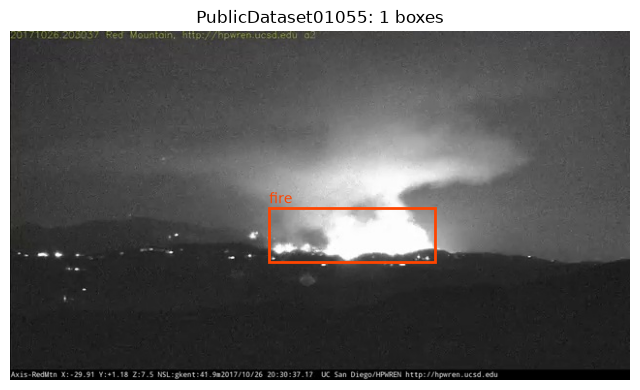

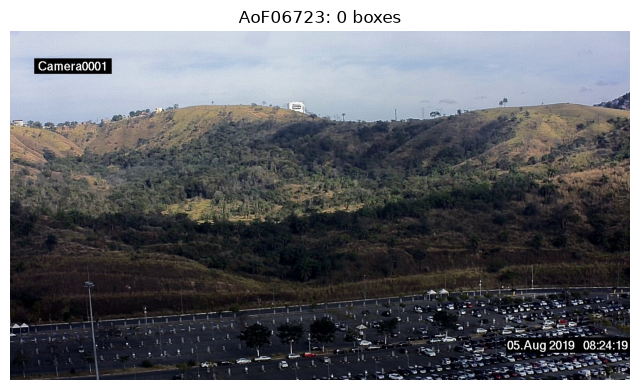

In [12]:
for name in ["AoF06978", "PublicDataset01055", "AoF06723"]:
    labels = read_labels(os.path.join(TEST_DIR, "labels", name + ".txt"))
    show_boxes(os.path.join(TEST_DIR, "images", name + ".jpg"), labels,
               title=f"{name}: {len(labels)} boxes")

## 3. Exploratory Data Analysis (EDA)

In [13]:
# Read every training label

def image_category(boxes):
    """Summarise an image as 'none', 'smoke', 'fire' or 'both' from its boxes."""
    classes = {box[0] for box in boxes}        # set of class ids present, e.g. {0, 1}
    if not classes:
        return "none"                          # no boxes at all
    if classes == {0}:
        return "smoke"
    if classes == {1}:
        return "fire"
    return "both"                              # contains 0 and 1

train_label_dir = os.path.join(TRAIN_DIR, "labels")
train_data = []                                # one entry per image
for filename in sorted(os.listdir(train_label_dir)):
    boxes = read_labels(os.path.join(train_label_dir, filename))
    train_data.append({"name": filename[:-4],   # filename without ".txt"
                       "boxes": boxes,
                       "category": image_category(boxes)})

print("Images loaded:", len(train_data))

Images loaded: 14122


  none:  6458 images (45.7%)
 smoke:  3836 images (27.2%)
  fire:   770 images (5.5%)
  both:  3058 images (21.7%)


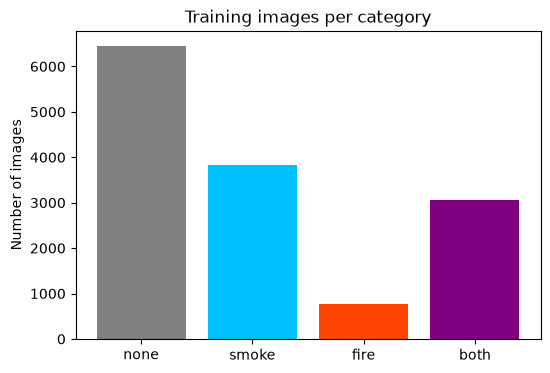

In [14]:
# Class distribution in the training set

from collections import Counter

category_counts = Counter(item["category"] for item in train_data)
order = ["none", "smoke", "fire", "both"]
for cat in order:
    n = category_counts[cat]
    print(f"{cat:>6}: {n:>5} images ({100 * n / len(train_data):.1f}%)")

plt.figure(figsize=(6, 4))
plt.bar(order, [category_counts[c] for c in order],
        color=["grey", "deepskyblue", "orangered", "purple"])
plt.title("Training images per category")
plt.ylabel("Number of images")
plt.show()

Total boxes: 17432
Smoke boxes: 7794
Fire boxes: 9638


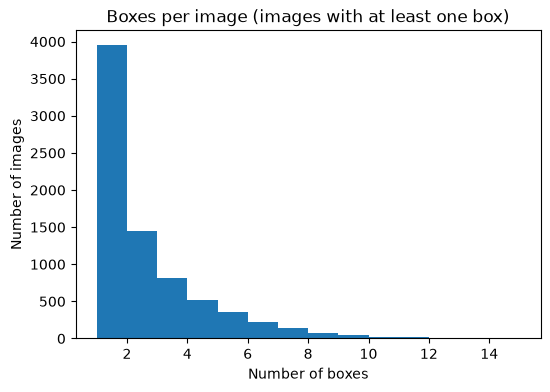

In [15]:
# Objects per class, and boxes per image

box_counts = Counter(box [0] for item in train_data for box in item["boxes"])
print("Total boxes:", sum(box_counts.values()))
print("Smoke boxes:", box_counts[0])
print("Fire boxes:", box_counts[1])

boxes_per_image = [len(item["boxes"]) for item in train_data if item["boxes"]]
plt.figure(figsize = (6, 4))
plt.hist(boxes_per_image, bins=range(1, 16))
plt.title("Boxes per image (images with at least one box)")
plt.xlabel("Number of boxes")
plt.ylabel("Number of images")
plt.show()

smoke: median size 0.374, 8.0% are tiny (< 5% of image side)
fire: median size 0.074, 33.4% are tiny (< 5% of image side)


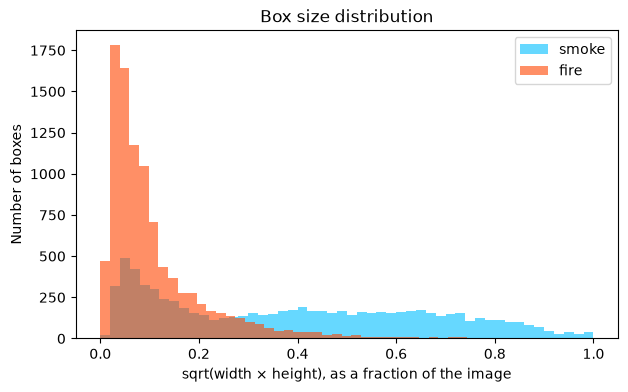

In [16]:
# Box Sizes
import numpy as np

plt.figure(figsize=(7, 4))
for class_id in [0, 1]:
    # sqrt(width * height) = a box's 'size' as a fraction of the image side
    sizes = [np.sqrt(b[3] * b[4]) for item in train_data for b in item["boxes"] if b[0] == class_id]
    plt.hist(sizes, bins=50, alpha=0.6, color=COLOURS[class_id], label=CLASS_NAMES[class_id])
    small = np.mean(np.array(sizes) < 0.05) * 100
    print(f"{CLASS_NAMES[class_id]}: median size {np.median(sizes):.3f}, {small:.1f}% are tiny (< 5% of image side)")

plt.title("Box size distribution")
plt.xlabel("sqrt(width × height), as a fraction of the image")
plt.ylabel("Number of boxes")
plt.legend()
plt.show()

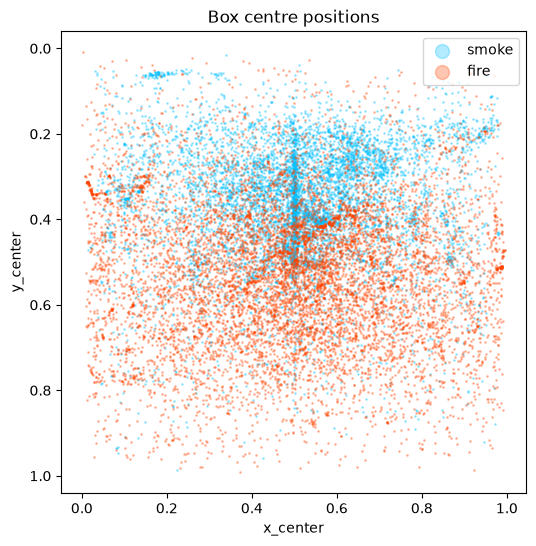

In [17]:
# Where objects appeear in the image

plt.figure(figsize=(6, 6))
for class_id in [0, 1]:
    xs = [b[1] for item in train_data for b in item["boxes"] if b[0] == class_id]
    ys = [b[2] for item in train_data for b in item["boxes"] if b[0] == class_id]
    plt.scatter(xs, ys, s=1, alpha=0.3, color=COLOURS[class_id], label=CLASS_NAMES[class_id])

plt.gca().invert_yaxis()                       # images have y=0 at the top
plt.title("Box centre positions")
plt.xlabel("x_center")
plt.ylabel("y_center")
plt.legend(markerscale=10)
plt.show()

## 4. Verify the train/validation/test split

In [18]:
import os
import kagglehub

DATA_DIR = kagglehub.dataset_download("sayedgamal99/smoke-fire-detection-yolo")
DATA_DIR = os.path.join(DATA_DIR, "data")

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")     # provided validation split
TEST_DIR  = os.path.join(DATA_DIR, "test")

for name, d in [("Train", TRAIN_DIR), ("Val", VAL_DIR), ("Test", TEST_DIR)]:
    print(f"{name} images:", len(os.listdir(os.path.join(d, "images"))),
          f"| {name} labels:", len(os.listdir(os.path.join(d, "labels"))))

Train images: 14122 | Train labels: 14122
Val images: 3099 | Val labels: 3099
Test images: 4306 | Test labels: 4306


In [19]:
## Load validation and test labels:

def load_split(split_dir):
    """Read every label file in a split folder (same as Step 3a) and return the list."""
    label_dir = os.path.join(split_dir, "labels")
    data = []
    for filename in sorted(os.listdir(label_dir)):
        boxes = read_labels(os.path.join(label_dir, filename))
        data.append({"name": filename[:-4],          # filename without ".txt"
                     "boxes": boxes,
                     "category": image_category(boxes)})
    return data

val_data = load_split(VAL_DIR)
test_data = load_split(TEST_DIR)
print("Train:", len(train_data), " Val:", len(val_data), " Test:", len(test_data))

Train: 14122  Val: 3099  Test: 4306


In [20]:
## Check class balance across splits:

print(f"{'category':>8} | {'train':>6} | {'val':>6} | {'test':>6}")
for cat in ["none", "smoke", "fire", "both"]:
    tr = 100 * sum(i["category"] == cat for i in train_data) / len(train_data)
    va = 100 * sum(i["category"] == cat for i in val_data) / len(val_data)
    te = 100 * sum(i["category"] == cat for i in test_data) / len(test_data)
    print(f"{cat:>8} | {tr:5.1f}% | {va:5.1f}% | {te:5.1f}%")

category |  train |    val |   test
    none |  45.7% |  44.4% |  46.6%
   smoke |  27.2% |  27.3% |  27.5%
    fire |   5.5% |   5.6% |   5.1%
    both |  21.7% |  22.7% |  20.8%


In [21]:
## Check for data leakage:

train_names = {i["name"] for i in train_data}
val_names   = {i["name"] for i in val_data}
test_names  = {i["name"] for i in test_data}

print("In train AND val: ", len(train_names & val_names))
print("In train AND test:", len(train_names & test_names))
print("In val AND test:  ", len(val_names & test_names))

In train AND val:  0
In train AND test: 0
In val AND test:   0


## 5. Target Encoding

In [22]:
#Turns images list of boxes into fixed size answer : [smoke, fire]
LABEL_NAMES = ["smoke", "fire"]           # class 0 and 1

def encode_multilabel(boxes):
    target = np.zeros(2, dtype=np.float32)  # two classes: smoke and fire
    for class_id, *_ in boxes:
        target[class_id] = 1.0
    return target

for split in (train_data, val_data, test_data):
    for item in split:
        item["target"] = encode_multilabel(item["boxes"])

y_train = np.array([item["target"] for item in train_data])
y_val   = np.array([item["target"] for item in val_data])
y_test  = np.array([item["target"] for item in test_data])
print ("y_train shape:", y_train.shape, "y_val shape:", y_val.shape, "y_test shape:", y_test.shape)

y_train shape: (14122, 2) y_val shape: (3099, 2) y_test shape: (4306, 2)


In [23]:
#some examples of the data, one for each category
for cat in ["none", "smoke", "fire", "both"]:
    item = next(i for i in train_data if i["category"] == cat)
    print(f"{item['name']:>22} | {cat:>5} | {len(item['boxes']):>2} boxes -> target {item['target']}")

              AoF00000 |  none |  0 boxes -> target [0. 0.]
              AoF00002 | smoke |  1 boxes -> target [1. 0.]
              AoF00001 |  fire |  1 boxes -> target [0. 1.]
              AoF04010 |  both |  6 boxes -> target [1. 1.]


In [24]:
positives = y_train.sum(axis=0)
negatives = len(y_train) - positives
pos_weight = negatives / positives
for name, p, w in zip(LABEL_NAMES, positives, pos_weight):
    print(f"{name:>5}: in {int(p)} / {len(y_train)} images ({100*p/len(y_train):.1f}%) -> pos_weight {w:.2f}")

smoke: in 6894 / 14122 images (48.8%) -> pos_weight 1.05
 fire: in 3828 / 14122 images (27.1%) -> pos_weight 2.69


## 6. Target Verification

In [25]:
for name, split, y, d in [("train", train_data, y_train, TRAIN_DIR),
                          ("val",   val_data,   y_val,   VAL_DIR),
                          ("test",  test_data,  y_test,  TEST_DIR)]:
    assert y.shape == (len(split), 2), f"{name}: wrong shape {y.shape}"
    assert set(np.unique(y)) <= {0.0, 1.0}, f"{name}: values other than 1 or 0"
    assert not np.isnan(y).any(), f"{name}: NaN in targets"
    image_names = {f[:-4] for f in os.listdir(os.path.join(d, "images"))}
    missing = [i["name"] for i in split if i["name"] not in image_names]
    assert not missing, f"{name}: {len(missing)} labels with no image, e.g. {missing[:3]}"
    print(f"{name}: OK - {y.shape}, only 0/1, no NaNs, every target has an image")

train: OK - (14122, 2), only 0/1, no NaNs, every target has an image
val: OK - (3099, 2), only 0/1, no NaNs, every target has an image
test: OK - (4306, 2), only 0/1, no NaNs, every target has an image


In [26]:
# 6b. Round trip: decode each target back to a category and compare with the EDA category
def decode_target(target):
    smoke, fire = int(target[0]), int(target[1])
    return {(0, 0): "none", (1, 0): "smoke", (0, 1): "fire", (1, 1): "both"}[(smoke, fire)]

for name, split in [("train", train_data), ("val", val_data), ("test", test_data)]:
    mismatches = [i["name"] for i in split if decode_target(i["target"]) != i["category"]]
    print(f"{name}: {len(mismatches)} mismatches out of {len(split)}")   # should be 0

train: 0 mismatches out of 14122
val: 0 mismatches out of 3099
test: 0 mismatches out of 4306


In [27]:
# 6c. Counts: % of images containing each class should agree with the EDA
# (smoke = smoke-only + both, fire = fire-only + both)
print(f"{'':>6} | {'smoke':>6} | {'fire':>6}")
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    smoke_pct, fire_pct = 100 * y.mean(axis=0)
    print(f"{name:>6} | {smoke_pct:5.1f}% | {fire_pct:5.1f}%")

tr = Counter(i["category"] for i in train_data)
print(f"Expected train from EDA: smoke {100*(tr['smoke']+tr['both'])/len(train_data):.1f}%, "
      f"fire {100*(tr['fire']+tr['both'])/len(train_data):.1f}%")

       |  smoke |   fire
 train |  48.8% |  27.1%
   val |  50.0% |  28.4%
  test |  48.3% |  25.9%
Expected train from EDA: smoke 48.8%, fire 27.1%


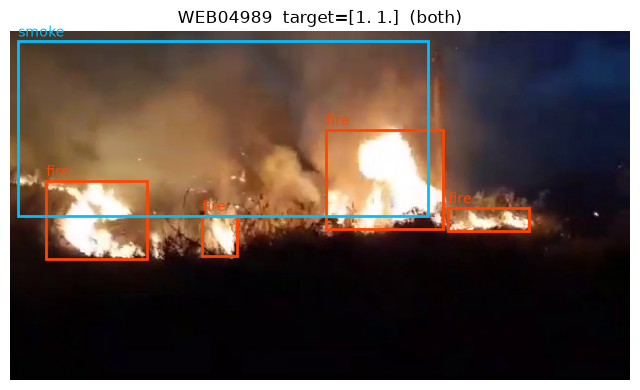

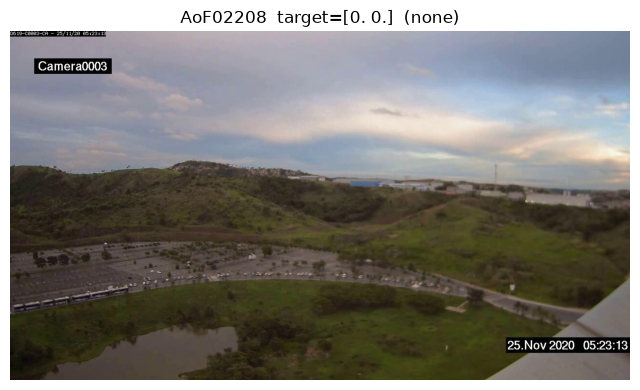

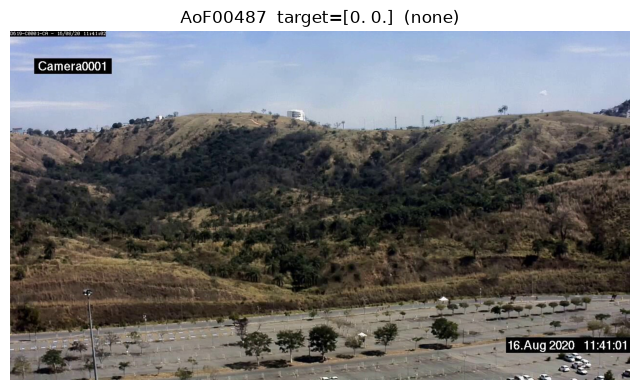

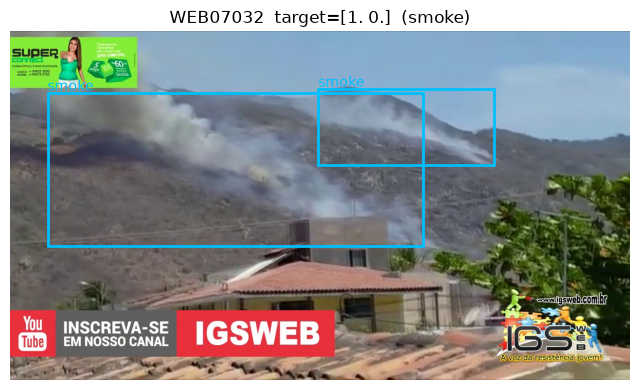

In [28]:
# 6d. Visual spot check: the target in the title should match what you can see in the picture
import random
random.seed(42)                                  # same images every run
for item in random.sample(train_data, 4):
    show_boxes(os.path.join(TRAIN_DIR, "images", item["name"] + ".jpg"), item["boxes"],
               title=f"{item['name']}  target={item['target']}  ({decode_target(item['target'])})")

## 7. Data Augmentation

In [ ]:
from torchvision import transforms

IMG_SIZE = 224

# Training transforms with Data Augmentation
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),   
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)), # Random crops to focus on different regions
    transforms.RandomHorizontalFlip(p=0.5),     # Flips image horizontally
    transforms.RandomRotation(degrees=15),      # Rotates image slightly
    transforms.ColorJitter(
        brightness = 0.2,
        contrast = 0.2,
        saturation = 0.2                        # Varies lighting/color for robustness
    ),
    transforms.ToTensor(),                     # Converts to tensor
    transforms.Normalize(mean=mean, std=std)    # Normalizes using computed dataset stats
])

# Validation/Test transforms without Data Augmentation
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

## 8. Input Pipeline

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMG_SIZE = 224      # fixed input size so images of different sizes can be stacked into a batch
BATCH_SIZE = 64     # hyperparameter, revisit in the experiments section

class FireSmokeDataset(Dataset):
    """Loads one image and its [smoke, fire] target on demand."""
    def __init__(self, items, img_dir, transform=None):
        self.items = items                  # list of dicts built in the EDA (name, boxes, category, target)
        self.img_dir = img_dir
        self.transform = transform
        # map label name -> real filename, so we don't assume every image is .jpg
        self.files = {f.rsplit(".", 1)[0]: f for f in os.listdir(img_dir)}

    def __len__(self):
        return len(self.items)              # DataLoader uses this to know the epoch size

    def __getitem__(self, i):
        item = self.items[i]
        path = os.path.join(self.img_dir, self.files[item["name"]])
        img = Image.open(path).convert("RGB")           # force 3 channels, in case any image is greyscale
        if self.transform:
            img = self.transform(img)                   # resize / tensor / normalize (and augment in section 8)
        return img, torch.from_numpy(item["target"])    # float32 [smoke, fire], the format BCE loss expects

In [32]:
img_dirs = {
    "train": os.path.join(TRAIN_DIR, "images"),
    "val":   os.path.join(VAL_DIR, "images"),
    "test":  os.path.join(TEST_DIR, "images")
}

# Resize and convert images to tensors with pixel values in [0, 1]
base_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor()
])

# Use num_workers=0 for compatibility with the Jupyter Notebook
stats_loader = DataLoader(
    FireSmokeDataset(train_data, img_dirs["train"], base_tf),
    batch_size=256,
    num_workers=0
)

# Accumulate channel sums and squared sums without loading
# the entire dataset into memory
s = torch.zeros(3)
sq = torch.zeros(3)
n = 0

for x, _ in stats_loader:
    s += x.sum(dim=(0, 2, 3))
    sq += (x ** 2).sum(dim=(0, 2, 3))
    n += x.shape[0] * x.shape[2] * x.shape[3]

mean = s / n
std = (sq / n - mean ** 2).sqrt()

print("Mean:", mean)
print("Std:", std)

Mean: tensor([0.3750, 0.3664, 0.3591])
Std: tensor([0.2726, 0.2729, 0.2960])


In [33]:
# resize -> tensor -> subtract mean, divide by std (zero-centred inputs help gradient descent and BatchNorm)
norm_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(),
                     T.Normalize(mean.tolist(), std.tolist())])
train_tf = norm_tf      # placeholder: section 8 replaces this with the augmenting version
eval_tf = norm_tf       # val and test must stay deterministic, so they never get augmentation

train_ds = FireSmokeDataset(train_data, img_dirs["train"], train_tf)
val_ds   = FireSmokeDataset(val_data,   img_dirs["val"],   eval_tf)
test_ds  = FireSmokeDataset(test_data,  img_dirs["test"],  eval_tf)

# shuffle only the training set; drop_last avoids a tiny final batch that makes BatchNorm statistics noisy
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(len(train_ds), len(val_ds), len(test_ds))

14122 3099 4306
